# 阶段 5：嵌入式实现 —— 能不能在板子上实时跑

> **阶段定位**：第 12–15 周｜过关产出（[阅读路线](../00-总览/阅读路线.md) 阶段 5）= **定点化位宽分析** + **资源/时序估算** + **板级或时序仿真结果**，并与阶段 4 的浮点指标对照。
>
> **诚实边界（先说在前面）**：本课题**没有 FPGA 开发板、没有综合报告**。本阶段交付的是**定点数值仿真 + 基于 F2 实测工艺的资源/时序换算 + 时序仿真图**，不是板级实测。凡「资源占用」「时钟周期」「实时性」都标注推算依据，不冒充实测；F2 的 −18 dB 也不与本课题的 −11 dB 横向比较（信号类型、带宽、判据全不同）。

## 阅读导航

| 节 | 内容 | 对应产出 |
|---|---|---|
| 0 | 环境、Q 格式工具、定点 RK4 仿真器 | 可复用的 `simulate_fixed()` |
| 1 | 字长扫描：等效阈值 λc(F) 如何漂移 | 位宽分析、推荐字长 |
| 2 | 定点下的检测：浮点工作点直接烧录会失败 | 重标定对照、Pd–λ0 曲线 |
| 3 | 资源/时序估算：op 数 → 时钟 → 并行 vs TDM | 时钟周期、资源估算表 |
| 4 | 时序仿真：流水线排程 + FIFO 分离数据流 | 时序仿真图 |
| 5 | 与阶段 4 浮点指标对照、边界与 JSON | 对照表、JSON |

**本阶段回答的四个问题**（阅读路线阶段 5「带着问题读」）：
1. 浮点 RK4 改定点要留多少位宽才不丢相变？——扫描 Q2.F 的 F，看等效阈值 λc 与异常窗口。
2. 一次迭代几个时钟周期？——数清每次 RK4 的乘/加次数，按 F2 的 24 ns/32 ns 换算。
3. 阵列多振子并行例化还是时分复用？——算完发现计算量极小，TDM 单核足够。
4. 判态模块放在数据流哪一级？——Poincaré 抽样后做帧级 pstd，与波形恢复用 FIFO 分离。

> **先记住四条结论**（后面用实跑支撑）：
> 1. **定点化改变的是等效阈值，不只是精度**：λc 从浮点的 ≈0.7335 漂到 F=8 的 ≈0.76、F=12 的 ≈0.77。
> 2. **浮点工作点不能直接烧录**：λ0=0.72 在定点下 Pd≈0；重标定到 λ0≈0.75 后 Pd≈0.92–1.00。
> 3. **字长存在甜点区 F=10–12**：F≤6 相变消失或动力学塌缩（F=4 全程 pstd≈0 的假周期）；F=8 有伪周期回弹；F≥14 阈值不再改善，纯属浪费资源。
> 4. **计算不是瓶颈，观测窗才是**：单帧 20000 步、约 1 μs/步 → 帧计算约 20 ms；而物理观测要 400 s，FPGA 再快也压缩不了这段物理时间。

## 0｜环境与定点仿真器

依次跑：**导入 → 路径/存图 → 全局参数 → Q 格式工具 → 定点 RK4 仿真器 → 冒烟自检**。

**Q 格式约定**：`Q2.F` 表示 2 位整数（含符号，范围 $[-2,2)$）+ F 位小数，总位宽 $W=2+F$。状态 $x,y\in[-1.5,1.5]$ 落在此范围。乘法用 `round(a*b/2^F)` 再截回整型，加法直接整型加——这就是硬件里 DSP 乘累加 + 舍入的行为模型。

> **为什么不用 `>>1` 算阻尼 0.5y**：算术右移对负数向下取整，会引入系统性偏置（`round` 才对称）；这个偏置在混沌区会被放大，是定点实现常见的暗坑。仿真器统一用 `round`。

In [1]:
# 0.1 导入与绘图设置
%matplotlib inline
import math, json, time
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt

plt.rcParams['font.sans-serif'] = ['Microsoft YaHei', 'SimHei', 'DejaVu Sans']
plt.rcParams['axes.unicode_minus'] = False
plt.rcParams['figure.dpi'] = 105
plt.rcParams['savefig.dpi'] = 135
plt.rcParams['axes.grid'] = True
plt.rcParams['grid.alpha'] = 0.28
plt.rcParams['mathtext.fontset'] = 'dejavusans'

In [2]:
# 0.2 路径与存图工具
def find_root():
    p = Path.cwd().resolve()
    for q in [p, *p.parents]:
        if (q / '00-总览/阅读路线.md').is_file() or (q / '阅读路线.md').is_file():
            return q
    return p

ROOT = find_root()
OUT = ROOT / '复现输出'
OUT.mkdir(exist_ok=True)

def savefig(name):
    path = OUT / name
    plt.savefig(path, bbox_inches='tight')   # 必须先 save 再 show
    print(f'[图] {path}')

In [3]:
# 0.3 全局参数：与阶段 2/3/4 同源，保证阈值可对照
DAMP, OMEGA = 0.5, 1.0
LAM0 = 0.72          # 阶段 2/3/4 的浮点工作点
H = 0.02             # 积分步长
PERIOD_STEPS = int(round(2 * math.pi / H))   # = 314，参考值：判据已改为在 τ=2πk 精确插值，不再按步数取整
SQRT_H = math.sqrt(H)
PSTD_TH = 0.08       # 阶段 2/3 的 pstd 判态门限

T_SIM = 300.0        # 字长扫描窗（无噪，找阈值用）
BURN_SIM = 150.0
T_DET = 300.0        # 检测对照窗（与阶段 3 盲区同量级，控制耗时）
BURN_DET = 150.0

SIGMA_DET = 0.05     # 阶段 4 的固定噪声 σ
GAMMA_SIG = 0.02     # 阶段 3/4 的测试信号幅值
NMC = 40             # 每工作点的蒙特卡洛次数（字长对照足够）

print(f'PERIOD_STEPS={PERIOD_STEPS}, H={H}, T_SIM={T_SIM}s, T_DET={T_DET}s, NMC={NMC}')
print(f'浮点工作点 λ0={LAM0}, 测试 γ={GAMMA_SIG}, σ={SIGMA_DET}')

PERIOD_STEPS=314, H=0.02, T_SIM=300.0s, T_DET=300.0s, NMC=40
浮点工作点 λ0=0.72, 测试 γ=0.02, σ=0.05


In [4]:
# 0.4 Q 格式工具：Q2.F 的乘法（乘后舍入）与标量量化
def qmul(a, b, S):
    """定点乘：a,b 为 Q2.F 整型，S=2^F；结果舍入回整型。"""
    return np.rint(a.astype(np.float64) * b.astype(np.float64) / S).astype(np.int64)

def to_q(v, S):
    """浮点 → Q2.F 整型。"""
    return np.rint(np.asarray(v) * S).astype(np.int64)

def from_q(q, S):
    """Q2.F 整型 → 浮点。"""
    return np.asarray(q, dtype=np.float64) / S

# 自检：Q2.12 的表示误差应 < 2^-13
S_chk = 1 << 12
print('Q2.12 量化误差 max =', round(float(np.abs(from_q(to_q(np.array([-1.5, -0.3, 0.7, 1.4]), S_chk), S_chk)
                                              - np.array([-1.5, -0.3, 0.7, 1.4])).max()), 6))

Q2.12 量化误差 max = 9.8e-05


In [5]:
# 0.5 定点 RK4 仿真器：与阶段 2 的 simulate 同方程，状态/导数全程 Q2.F
def simulate_fixed(lam, gamma, theta, sigma, noise, F,
                   h=H, t_end=T_SIM, burn=BURN_SIM):
    """定点 Duffing + RK4，返回 Poincaré 截面后半段的 pstd（每路一条）。

    lam/gamma/theta 支持广播；noise 形状必须 >= (steps, m)，按列取前 m 路。
    F 为小数位宽，总位宽 W=2+F。
    """
    lam = np.atleast_1d(np.asarray(lam, float))
    gamma = np.atleast_1d(np.asarray(gamma, float))
    theta = np.atleast_1d(np.asarray(theta, float))
    lam, gamma, theta = np.broadcast_arrays(lam, gamma, theta)
    m = lam.size
    steps = int(round(t_end / h))
    burn_steps = int(round(burn / h))
    S = 1 << F

    x = np.zeros(m, dtype=np.int64)
    y = np.zeros(m, dtype=np.int64)
    poincare = []
    TWOPI = 2 * math.pi
    idx_prev = 0

    for i in range(steps):
        t = i * h
        # 策动力 + 噪声，定点化（ Drive = lam cos t + gamma cos(t+theta) ）
        drive = lam * math.cos(t) + gamma * np.cos(t + theta)
        d_q = to_q(drive, S) + to_q(sigma * SQRT_H * noise[i, :m], S)

        def f(xq, yq):
            x2 = qmul(xq, xq, S)
            x3 = qmul(x2, xq, S)
            x5 = qmul(x3, x2, S)
            # y' = -0.5*y + x^3 - x^5 + drive；0.5y 用 round 而非 >>1（避免负向偏置）
            return yq, -np.rint(0.5 * yq).astype(np.int64) + x3 - x5 + d_q

        k1x, k1y = f(x, y)
        k2x, k2y = f(x + to_q(h * k1x, 1), y + to_q(h * k1y, 1))
        k3x, k3y = f(x + to_q(h * k2x, 1), y + to_q(h * k2y, 1))
        k4x, k4y = f(x + to_q(h * k3x, 1), y + to_q(h * k3y, 1))

        x_prev = from_q(x, S).copy()          # 更新前存档（浮点），供 2π 时刻插值
        x = x + to_q(h / 6 * (k1x + 2*k2x + 2*k3x + k4x), 1)
        y = y + to_q(h / 6 * (k1y + 2*k2y + 2*k3y + k4y), 1)

        if i >= burn_steps:
            # 精确落在 τ=2πk 上取截面（按步数取整会引入相位漂移伪 pstd）
            idx = int(math.floor((t + h) / TWOPI + 1e-12))
            if idx != idx_prev and idx > 0:
                frac = min(max((TWOPI * idx - t) / h, 0.0), 1.0)
                x_now = from_q(x, S)
                poincare.append(x_prev + frac * (x_now - x_prev))
                idx_prev = idx

    p = np.asarray(poincare)
    return p[len(p)//2:].std(axis=0)

In [6]:
# 0.6 冒烟自检：混沌态 pstd 应大、周期态应小（无噪）
steps0 = int(round(T_SIM / H))
zero_noise = np.zeros((steps0, 2))
p_chaos = simulate_fixed([0.70, 0.72], 0, 0, 0, zero_noise, F=12)
p_period = simulate_fixed([0.80, 0.82], 0, 0, 0, zero_noise, F=12)
print(f'F=12 混沌端 (λ=0.70/0.72) pstd = {np.round(p_chaos, 4).tolist()}')
print(f'F=12 周期端 (λ=0.80/0.82) pstd = {np.round(p_period, 4).tolist()}')
assert p_chaos.mean() > PSTD_TH and p_period.mean() < PSTD_TH, '定点仿真器方向不对'
print('[OK] 定点仿真器方向正确')

# 关键预告：浮点的周期点 λ=0.76 在 F=12 下仍是混沌！
p_at_float_period = simulate_fixed([0.76], 0, 0, 0, zero_noise[:, :1], F=12)[0]
print(f'⚠ 浮点周期点 λ=0.76 在 F=12 下 pstd={p_at_float_period:.4f}（>0.08 仍是混沌）')
print('  → 定点化的等效阈值已漂移，第 1/2 节将系统量化这一点')

F=12 混沌端 (λ=0.70/0.72) pstd = [0.4265, 0.4294]
F=12 周期端 (λ=0.80/0.82) pstd = [0.0021, 0.0015]
[OK] 定点仿真器方向正确


⚠ 浮点周期点 λ=0.76 在 F=12 下 pstd=0.4339（>0.08 仍是混沌）
  → 定点化的等效阈值已漂移，第 1/2 节将系统量化这一点


## 1｜字长扫描：等效阈值怎么漂

**做法**：固定无噪，对 $F\in\{4,6,8,10,12,14,16,18\}$ 各扫一遍 $\lambda\in[0.70,0.84]$，取首个 $p_{\rm std}<0.1$ 的 $\lambda$ 当作**定点等效阈值** $\lambda_c(F)$，与浮点阈值带 0.733–0.734 对照。

**注意**：这里刻意**不加噪声**——阈值是系统动力学本身的属性，加噪会模糊判读。噪声留到下一节的检测实验。

> 实跑观察（三种失效模式，都要认得）：
> - **F=4 动力学塌缩**：$p_{\rm std}$ 全程≈0（状态被量化锁死在定点），看起来处处"周期"其实是假象；
> - **F=6 相变消失**：噪声般的量化误差压过相变，整个 λ 网格都混沌；
> - **F=8 伪周期回弹**：λ=0.76 已相变，但 λ=0.80 又弹回混沌——有限字长动力学的伪窗口，不是信号；
> - **F=10–12 甜点区**：阈值稳定在 ≈0.77（比浮点高 3–5%），无回弹，够用且省资源。

In [7]:
# 1.1 全字长阈值扫描（无噪）
F_GRID = [4, 6, 8, 10, 12, 14, 16, 18]
LAM_GRID = np.round(np.arange(0.70, 0.845, 0.01), 3)

scan = {}
_t0 = time.time()
for F in F_GRID:
    vals = []
    for lam in LAM_GRID:
        vals.append(float(simulate_fixed([lam], 0, 0, 0, np.zeros((steps0, 1)), F)[0]))
    scan[F] = np.array(vals)
    crit = next((float(l) for l, v in zip(LAM_GRID, vals) if v < 0.1), None)
    print(f'F={F:2d} (W={2+F:2d}): λc ≈ {crit}   pstd@0.72={vals[2]:.3f}  pstd@0.80={vals[10]:.3f}')
print(f'扫描耗时 {time.time()-_t0:.1f} s')

F= 4 (W= 6): λc ≈ 0.7   pstd@0.72=0.000  pstd@0.80=0.000


F= 6 (W= 8): λc ≈ None   pstd@0.72=0.173  pstd@0.80=0.381


F= 8 (W=10): λc ≈ 0.76   pstd@0.72=0.534  pstd@0.80=0.006


F=10 (W=12): λc ≈ 0.77   pstd@0.72=0.359  pstd@0.80=0.004


F=12 (W=14): λc ≈ 0.77   pstd@0.72=0.429  pstd@0.80=0.002


F=14 (W=16): λc ≈ 0.77   pstd@0.72=0.432  pstd@0.80=0.000


F=16 (W=18): λc ≈ 0.77   pstd@0.72=0.272  pstd@0.80=0.000


F=18 (W=20): λc ≈ 0.77   pstd@0.72=0.324  pstd@0.80=0.000
扫描耗时 209.1 s


In [8]:
# 1.2 提取等效阈值 λc(F)（首个 pstd<0.1）
lam_c = {}
for F in F_GRID:
    hit = np.where(scan[F] < 0.1)[0]
    lam_c[F] = float(LAM_GRID[hit[0]]) if len(hit) else None

# 失效模式识别：塌缩（全程≈0）/ 无相变（全程混沌）/ 伪周期回弹（先低后高）
collapse = {F: bool(np.all(scan[F] < 0.05)) for F in F_GRID}
no_transition = {F: bool(np.all(scan[F] >= 0.1)) for F in F_GRID}

spurious = {}
for F in F_GRID:
    low = np.where(scan[F] < 0.1)[0]
    spur = None
    if len(low) and not collapse[F]:
        after = low[low > low[0] + 1]
        rebound = after[after < len(LAM_GRID) - 1]
        rebound = rebound[scan[F][rebound + 1] > 0.1] if len(rebound) else []
        spur = float(LAM_GRID[rebound[0]]) if len(rebound) else None
    spurious[F] = spur

print('等效阈值 λc(F):', lam_c)
print('动力学塌缩 F:', [F for F, v in collapse.items() if v])
print('无相变 F:', [F for F, v in no_transition.items() if v])
print('伪周期回弹:', {F: s for F, s in spurious.items() if s is not None})

等效阈值 λc(F): {4: 0.7, 6: None, 8: 0.76, 10: 0.77, 12: 0.77, 14: 0.77, 16: 0.77, 18: 0.77}
动力学塌缩 F: [4]
无相变 F: [6]
伪周期回弹: {8: 0.8}


[图] C:\Users\22902\WorkBuddy\毕设\复现输出\阶段5-位宽扫描与阈值漂移.png


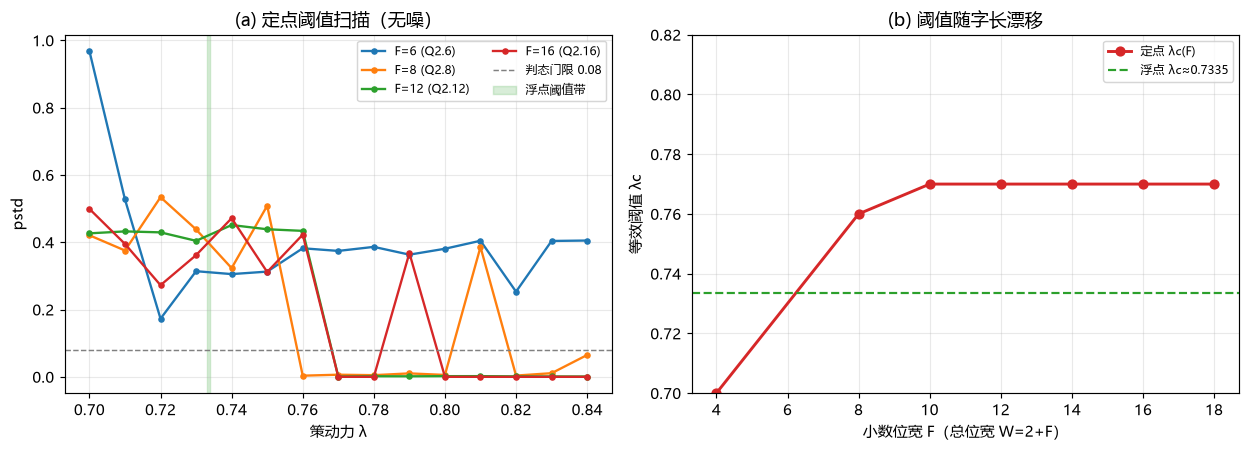

In [9]:
# 1.3 图：阈值漂移 + 各字长扫描曲线
fig, axes = plt.subplots(1, 2, figsize=(12, 4.4))

ax = axes[0]
for F in [6, 8, 12, 16]:
    if F in scan:
        ax.plot(LAM_GRID, scan[F], marker='o', ms=3.5, lw=1.6, label=f'F={F} (Q2.{F})')
ax.axhline(PSTD_TH, color='grey', ls='--', lw=1, label=f'判态门限 {PSTD_TH}')
ax.axvspan(0.733, 0.734, color='tab:green', alpha=0.18, label='浮点阈值带')
ax.set(xlabel='策动力 λ', ylabel='pstd', title='(a) 定点阈值扫描（无噪）')
ax.legend(fontsize=8, ncol=2)

ax = axes[1]
valid = [(F, v) for F, v in lam_c.items() if v is not None]
ax.plot([F for F, _ in valid], [v for _, v in valid], 'o-', color='tab:red', lw=2, ms=6, label='定点 λc(F)')
ax.axhline(0.7335, color='tab:green', ls='--', lw=1.5, label='浮点 λc≈0.7335')
ax.set(xlabel='小数位宽 F（总位宽 W=2+F）', ylabel='等效阈值 λc',
       title='(b) 阈值随字长漂移', ylim=(0.70, 0.82))
ax.legend(fontsize=8)
plt.tight_layout()
savefig('阶段5-位宽扫描与阈值漂移.png')
plt.show()

## 2｜定点下的检测：工作点必须重标定

**这是本阶段最关键的一节。** 阶段 2–4 把工作点定在 $\lambda_0=0.72$（略低于浮点阈值 0.7335），加信号 $\gamma=0.02$ 后越过阈值触发相变。但如果把这组参数**原样烧进定点 FPGA**，由第 1 节知定点阈值已抬到 0.76–0.77，$\lambda_0+\gamma=0.74$ 根本够不到——检测直接失效。

**实验**：固定 $\sigma=0.05$、$\gamma=0.02$、$F=12$，扫 $\lambda_0\in[0.72,0.78]$，每个点跑 $N_{MC}=40$ 次：
- H0（$\gamma=0$）的 pstd 分布取 5% 分位数当门限（沿用阶段 4 的 H0 反解纪律）；
- H1（$\gamma=0.02$）低于该门限即判检出，$P_d$ = 命中比例。

> **读法**：$\lambda_0=0.72$（浮点工作点）应接近 $P_d\approx0$；$\lambda_0\approx0.75$ 应恢复到 $P_d\gtrsim0.9$；$\lambda_0\ge0.77$ 时 H0 自己就相变了，门限塌缩、$P_d$ 再次失效——这是"工作点不能太高"的另一侧边界。

In [10]:
# 2.1 工作点扫描：H0 定门限 + H1 算 Pd（F=12）
F_DET = 12
S_DET = 1 << F_DET
LAM0_GRID = np.round(np.arange(0.72, 0.781, 0.01), 3)
steps_d = int(round(T_DET / H))
rng = np.random.default_rng(2026)
noise_mc = rng.standard_normal((steps_d, NMC))

pd_fixed, h0_med, h1_med, gate = [], [], [], []
for l0 in LAM0_GRID:
    p0 = simulate_fixed([l0]*NMC, 0, 0, SIGMA_DET, noise_mc, F_DET,
                        t_end=T_DET, burn=BURN_DET)
    p1 = simulate_fixed([l0+GAMMA_SIG]*NMC, 0, 0, SIGMA_DET, noise_mc, F_DET,
                        t_end=T_DET, burn=BURN_DET)
    th = float(np.quantile(p0, 0.05))
    pd_fixed.append(float((p1 < th).mean()))
    h0_med.append(float(np.median(p0)))
    h1_med.append(float(np.median(p1)))
    gate.append(th)
    print(f'λ0={l0:.2f}: H0med={h0_med[-1]:.3f} H1med={h1_med[-1]:.3f} gate={th:.3f} Pd={pd_fixed[-1]:.2f}')

λ0=0.72: H0med=0.407 H1med=0.415 gate=0.295 Pd=0.00


λ0=0.73: H0med=0.427 H1med=0.387 gate=0.330 Pd=0.23


λ0=0.74: H0med=0.415 H1med=0.383 gate=0.342 Pd=0.23


λ0=0.75: H0med=0.387 H1med=0.003 gate=0.311 Pd=0.82


λ0=0.76: H0med=0.383 H1med=0.003 gate=0.270 Pd=0.90


λ0=0.77: H0med=0.003 H1med=0.002 gate=0.002 Pd=0.05


λ0=0.78: H0med=0.003 H1med=0.002 gate=0.002 Pd=0.28


In [11]:
# 2.2 找出最佳重标定工作点（Pd 最高的 λ0）
best_i = int(np.argmax(pd_fixed))
LAM0_BEST = float(LAM0_GRID[best_i])
LAM0_FLOAT = 0.72
PD_FLOAT = pd_fixed[0]
PD_BEST = pd_fixed[best_i]
print(f'浮点工作点 λ0={LAM0_FLOAT}: Pd={PD_FLOAT:.2f}（定点下失效）')
print(f'重标定 λ0={LAM0_BEST}: Pd={PD_BEST:.2f}')
print(f'阈值漂移量 Δλc = {lam_c[F_DET] - 0.7335:.3f}')

浮点工作点 λ0=0.72: Pd=0.00（定点下失效）
重标定 λ0=0.76: Pd=0.90
阈值漂移量 Δλc = 0.036


[图] C:\Users\22902\WorkBuddy\毕设\复现输出\阶段5-定点检测与重标定.png


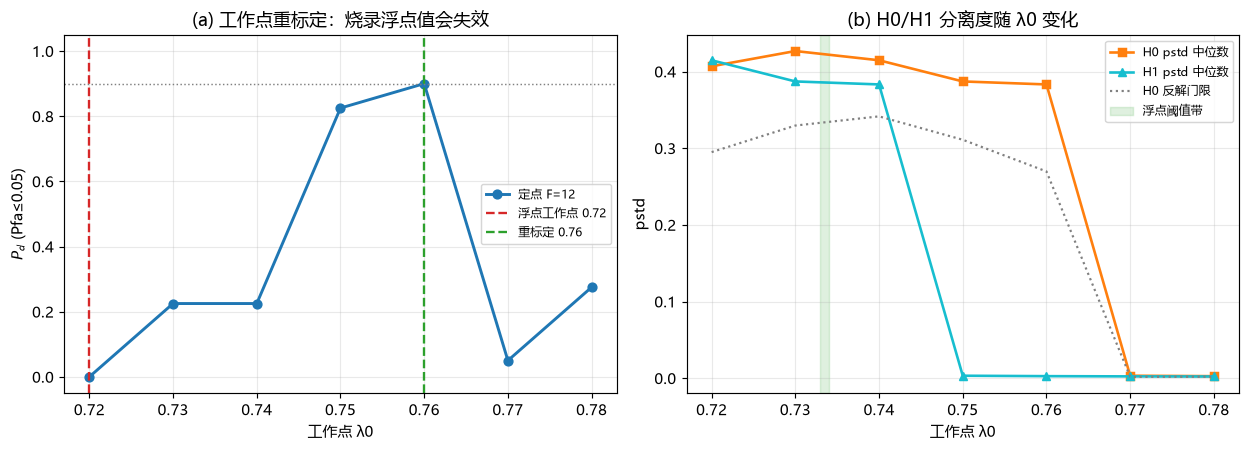

In [12]:
# 2.3 图：Pd–λ0 重标定曲线 + H0/H1 分布
fig, axes = plt.subplots(1, 2, figsize=(12, 4.4))

ax = axes[0]
ax.plot(LAM0_GRID, pd_fixed, 'o-', color='tab:blue', lw=2, ms=6, label='定点 F=12')
ax.axvline(LAM0_FLOAT, color='tab:red', ls='--', lw=1.6, label=f'浮点工作点 {LAM0_FLOAT}')
ax.axvline(LAM0_BEST, color='tab:green', ls='--', lw=1.6, label=f'重标定 {LAM0_BEST}')
ax.axhline(0.9, color='grey', ls=':', lw=1)
ax.set(xlabel='工作点 λ0', ylabel='$P_d$ (Pfa≤0.05)',
       title='(a) 工作点重标定：烧录浮点值会失效', ylim=(-0.05, 1.05))
ax.legend(fontsize=8)

ax = axes[1]
ax.plot(LAM0_GRID, h0_med, 's-', color='tab:orange', lw=1.8, ms=5, label='H0 pstd 中位数')
ax.plot(LAM0_GRID, h1_med, '^-', color='tab:cyan', lw=1.8, ms=5, label='H1 pstd 中位数')
ax.plot(LAM0_GRID, gate, ':', color='grey', lw=1.5, label='H0 反解门限')
ax.axvspan(0.733, 0.734, color='tab:green', alpha=0.15, label='浮点阈值带')
ax.set(xlabel='工作点 λ0', ylabel='pstd', title='(b) H0/H1 分离度随 λ0 变化')
ax.legend(fontsize=8)
plt.tight_layout()
savefig('阶段5-定点检测与重标定.png')
plt.show()

## 3｜资源与时序估算：从 op 数到时钟周期

**纪律**：以下数字是**基于 F2 实测工艺的换算**，不是本机综合结果。F2 在 Xilinx Zynq-7045、250 MHz 时钟下实测「一次乘法 24 ns、一次加法 32 ns」，其 5 级 RTRK4 迭代约 1440 ns（约 694 kHz 采样率）。本课题用的经典 RK4（4 级）算子数更少，按其工艺线性换算即可。

**每级导数的 op 数**（状态 $v=(x,y)$，$y'= -0.5y + x^3 - x^5 + {\rm drive}$）：
- $x^2=x\cdot x$、$x^3=x^2\cdot x$、$x^5=x^3\cdot x^2$ → 3 乘；
- $0.5y$（常数系数，保守按 1 乘计）→ 1 乘；
- $-0.5y+x^3-x^5+{\rm drive}$ → 3 加；
- 每级小计 **4 乘 + 3 加**，4 级 = 16 乘 + 12 加；
- 末态组合 $x+\frac h6(k_1+2k_2+2k_3+k_4)$ 对 x、y 各一次：把 $h/6$ 预乘进 k 后，各 3 加 + 1 乘 → 合计 2 乘 + 6 加；
- **单振子单步合计：18 乘 + 18 加**。

> **关键判断**：F2 的 RTRK4 是 5 级且强耦合双振子（状态 4 维），仍需 1440 ns/步；本课题单振子 4 维以下、18+18 op，换算约 1 μs/步。一帧 20000 步约 20 ms——**对 400 s 物理窗而言，计算时间可以忽略**。因此阵列推荐 **TDM 单核 + FIFO**（省资源），而非多振子并行例化。

In [13]:
# 3.1 op 数与时钟换算（基于 F2 实测工艺）
OPS_PER_STAGE = (4, 3)          # (乘, 加)
N_STAGES = 4                    # 经典 RK4
MUL_COMB, ADD_COMB = 2, 6       # 末态组合
OPS_MUL = OPS_PER_STAGE[0] * N_STAGES + MUL_COMB   # 18
OPS_ADD = OPS_PER_STAGE[1] * N_STAGES + ADD_COMB   # 18

T_MUL_NS, T_ADD_NS = 24.0, 32.0       # F2 实测（Zynq-7045, 250MHz）
CLK_NS = 4.0                          # 250 MHz
ITER_NS = OPS_MUL * T_MUL_NS + OPS_ADD * T_ADD_NS
CYCLES = ITER_NS / CLK_NS

STEPS_PER_FRAME = int(round(400.0 / H))   # 阶段 4 的 T=400s
FRAME_MS_PAR = STEPS_PER_FRAME * ITER_NS / 1e6
FRAME_MS_TDM = FRAME_MS_PAR * 3            # 三振子时分复用

print(f'单步 op: {OPS_MUL} 乘 + {OPS_ADD} 加 = {OPS_MUL+OPS_ADD} op')
print(f'按 F2 工艺换算: {ITER_NS:.0f} ns/步 ≈ {CYCLES:.0f} 时钟 @250MHz（{CLK_NS}ns）')
print(f'一帧 {STEPS_PER_FRAME} 步: 单振子 {FRAME_MS_PAR:.1f} ms / 三振子TDM {FRAME_MS_TDM:.1f} ms')
print(f'物理观测窗 400 s → 计算加速比（单振子）≈ {400/(FRAME_MS_PAR/1000):.0f}×')

单步 op: 18 乘 + 18 加 = 36 op
按 F2 工艺换算: 1008 ns/步 ≈ 252 时钟 @250MHz（4.0ns）
一帧 20000 步: 单振子 20.2 ms / 三振子TDM 60.5 ms
物理观测窗 400 s → 计算加速比（单振子）≈ 19841×


In [14]:
# 3.2 三振子阵列：并行例化 vs 时分复用（TDM）
N_OSC = 3
res = {
    '并行例化': {
        'DSP乘数': OPS_MUL * N_OSC,
        '帧计算_ms': FRAME_MS_PAR,
        '相对资源': N_OSC,
        '帧延迟_ms': FRAME_MS_PAR,
    },
    'TDM单核': {
        'DSP乘数': OPS_MUL,
        '帧计算_ms': FRAME_MS_TDM,
        '相对资源': 1,
        '帧延迟_ms': FRAME_MS_TDM,
    },
}
for k, v in res.items():
    print(f'{k}: DSP乘数={v["DSP乘数"]}, 帧计算={v["帧计算_ms"]:.1f} ms, 相对资源={v["相对资源"]}×')
print('结论：两种方案帧计算都远小于 400 s 物理窗 → 选 TDM 省资源；需帧缓存保证三路时间对齐。')

并行例化: DSP乘数=54, 帧计算=20.2 ms, 相对资源=3×
TDM单核: DSP乘数=18, 帧计算=60.5 ms, 相对资源=1×
结论：两种方案帧计算都远小于 400 s 物理窗 → 选 TDM 省资源；需帧缓存保证三路时间对齐。


[图] C:\Users\22902\WorkBuddy\毕设\复现输出\阶段5-资源时序估算.png


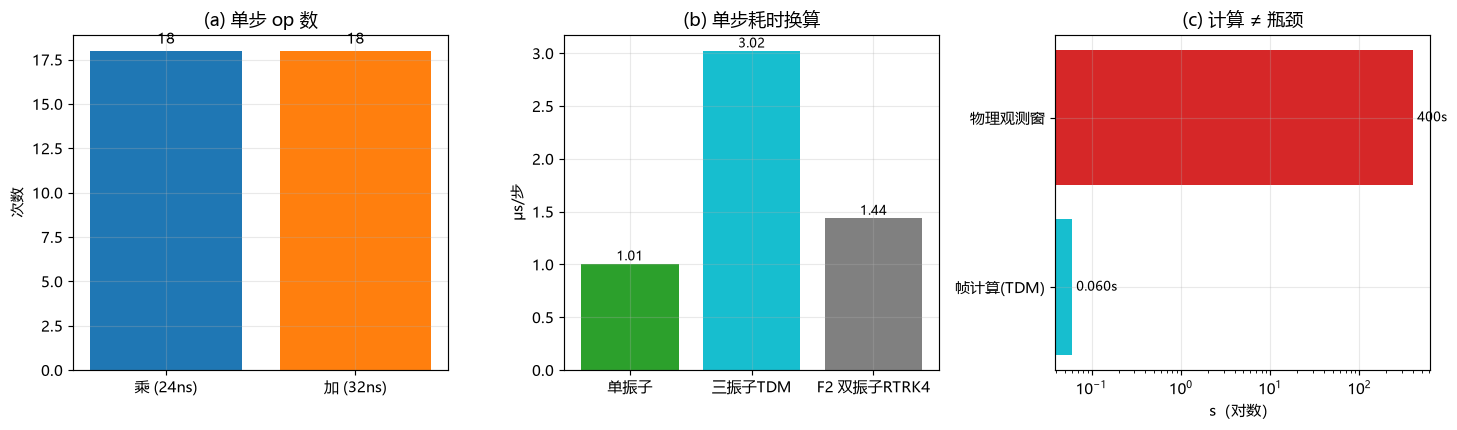

In [15]:
# 3.3 图：op 分解 + 时钟换算 + 计算时间 vs 物理窗
fig, axes = plt.subplots(1, 3, figsize=(14, 4.2))

ax = axes[0]
ax.bar(['乘 (24ns)', '加 (32ns)'], [OPS_MUL, OPS_ADD], color=['tab:blue', 'tab:orange'])
ax.set(title='(a) 单步 op 数', ylabel='次数')
for i, v in enumerate([OPS_MUL, OPS_ADD]):
    ax.text(i, v + 0.4, str(v), ha='center', fontsize=10)

ax = axes[1]
labels = ['单振子', '三振子TDM', 'F2 双振子RTRK4']
vals = [ITER_NS/1000, ITER_NS*3/1000, 1.44]
ax.bar(labels, vals, color=['tab:green', 'tab:cyan', 'grey'])
ax.set(title='(b) 单步耗时换算', ylabel='μs/步')
for i, v in enumerate(vals):
    ax.text(i, v + 0.03, f'{v:.2f}', ha='center', fontsize=9)

ax = axes[2]
ax.barh(['帧计算(TDM)', '物理观测窗'], [FRAME_MS_TDM/1000, 400], color=['tab:cyan', 'tab:red'])
ax.set(title='(c) 计算 ≠ 瓶颈', xlabel='s（对数）')
ax.set_xscale('log')
ax.text(FRAME_MS_TDM/1000, 0, f' {FRAME_MS_TDM/1000:.3f}s', va='center', fontsize=9)
ax.text(400, 1, ' 400s', va='center', fontsize=9)

plt.tight_layout()
savefig('阶段5-资源时序估算.png')
plt.show()

## 4｜时序仿真：流水线排程与数据流分路

**回答"判态模块放在数据流哪一级"**：分三级流水——
1. **RK4 积分级**（每步执行，1 μs/步）：输出状态 x；
2. **Poincaré 抽样式判态级**（每 314 步一次）：按驱动周期相位抽样，攒够一帧后算 pstd，与门限比较——这是阶段 3 的判据落地，放在积分级之后、以帧为节律；
3. **波形恢复级**（F2 的 FIFO 分离思想）：ADC 原始数据同时写入 FIFO，触发时才上传给上位机做连续重构——判态模块**不碰原始波形**，避免分段计算造成畸变。

**图下半部**是单步流水线的时序仿真排程：4 个 RK4 级（K1–K4）+ 末态组合，用同一条 MAC 流水分 5 拍完成（借鉴 F2「一条流水线跑 5 次」的复用思路）。

[图] C:\Users\22902\WorkBuddy\毕设\复现输出\阶段5-时序仿真与数据流.png


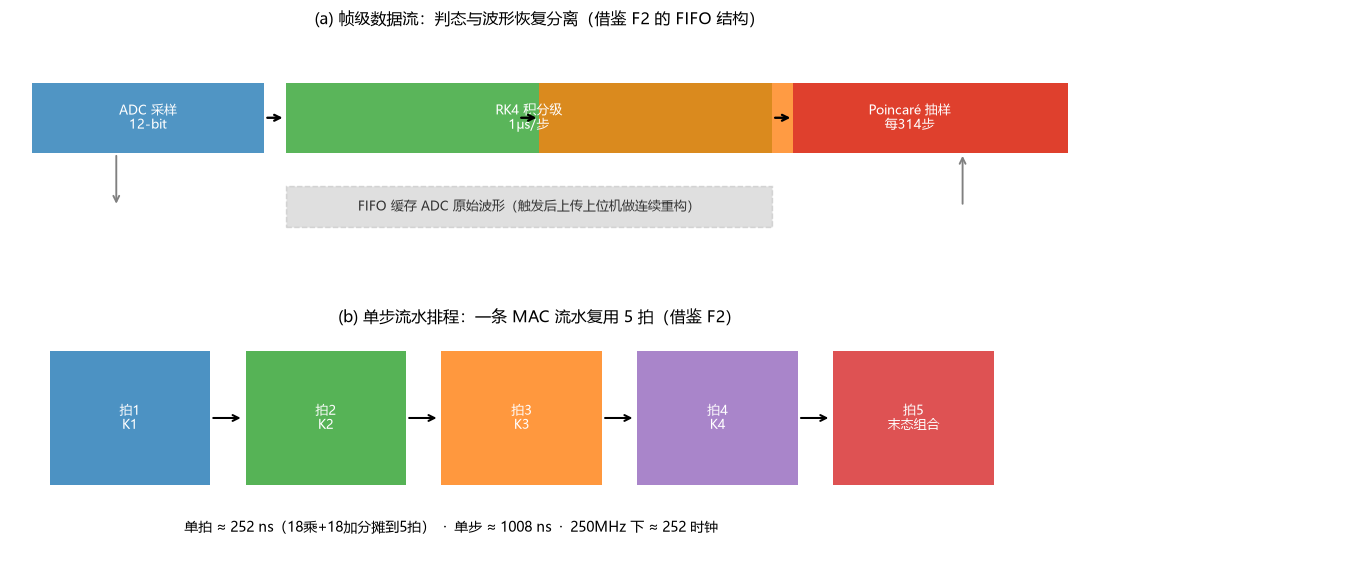

In [16]:
# 4.1 时序仿真图：帧级数据流 + 单步流水排程
fig = plt.figure(figsize=(13, 6.5))
gs = fig.add_gridspec(2, 1, height_ratios=[1.0, 1.1], hspace=0.42)

# --- 上：帧级数据流（三级流水 + FIFO 分离）
ax1 = fig.add_subplot(gs[0])
ax1.set_title('(a) 帧级数据流：判态与波形恢复分离（借鉴 F2 的 FIFO 结构）', fontsize=11)
stages = [
    (0.02, 0.22, 'ADC 采样\n12-bit', 'tab:blue'),
    (0.26, 0.46, 'RK4 积分级\n1μs/步', 'tab:green'),
    (0.50, 0.70, 'Poincaré 抽样\n每314步', 'tab:orange'),
    (0.74, 0.96, '帧级 pstd\n判态输出 0/1', 'tab:red'),
]
for x, w, label, color in stages:
    ax1.add_patch(plt.Rectangle((x, 0.42), w, 0.34, facecolor=color, alpha=0.78, edgecolor='none'))
    ax1.text(x + w/2, 0.59, label, ha='center', va='center', fontsize=9, color='white')
for x in [0.24, 0.48, 0.72]:
    ax1.annotate('', xy=(x+0.02, 0.59), xytext=(x, 0.59),
                 arrowprops=dict(arrowstyle='->', lw=1.6, color='black'))
# FIFO 旁路
ax1.add_patch(plt.Rectangle((0.26, 0.06), 0.46, 0.20, facecolor='grey', alpha=0.25, edgecolor='grey', ls='--'))
ax1.text(0.49, 0.16, 'FIFO 缓存 ADC 原始波形（触发后上传上位机做连续重构）',
         ha='center', va='center', fontsize=9, color='#333')
ax1.annotate('', xy=(0.10, 0.16), xytext=(0.10, 0.42),
             arrowprops=dict(arrowstyle='->', lw=1.3, color='grey'))
ax1.annotate('', xy=(0.90, 0.42), xytext=(0.90, 0.16),
             arrowprops=dict(arrowstyle='->', lw=1.3, color='grey'))
ax1.set_xlim(0, 1); ax1.set_ylim(0, 1); ax1.axis('off')

# --- 下：单步流水线排程（5 拍复用一条 MAC 流水）
ax2 = fig.add_subplot(gs[1])
ax2.set_title('(b) 单步流水排程：一条 MAC 流水复用 5 拍（借鉴 F2）', fontsize=11)
beats = ['拍1\nK1', '拍2\nK2', '拍3\nK3', '拍4\nK4', '拍5\n末态组合']
colors = ['tab:blue', 'tab:green', 'tab:orange', 'tab:purple', 'tab:red']
for j, (label, color) in enumerate(zip(beats, colors)):
    ax2.add_patch(plt.Rectangle((j, 0), 0.82, 1, facecolor=color, alpha=0.8, edgecolor='none'))
    ax2.text(j+0.41, 0.5, label, ha='center', va='center', fontsize=9, color='white')
    if j < 4:
        ax2.annotate('', xy=(j+0.99, 0.5), xytext=(j+0.82, 0.5),
                     arrowprops=dict(arrowstyle='->', lw=1.4, color='black'))
ax2.text(2.05, -0.35, f'单拍 ≈ {ITER_NS/N_STAGES-0:.0f} ns（18乘+18加分摊到5拍）  ·  单步 ≈ {ITER_NS:.0f} ns  ·  250MHz 下 ≈ {CYCLES:.0f} 时钟',
         ha='center', fontsize=9.5)
ax2.set_xlim(-0.2, 5.2); ax2.set_ylim(-0.55, 1.15); ax2.axis('off')

savefig('阶段5-时序仿真与数据流.png')
plt.show()

## 5｜与阶段 4 浮点指标对照 + 边界

**对照原则**：定点数字**不与文献横向比较**，只与本课题阶段 4 的浮点结果同条件对照（同 $\sigma=0.05$、$\gamma=0.02$、$h=0.02$、pstd 判据、H0 反解门限）。差异全部来自「量化 → 等效阈值漂移 → 工作点需重标定」。

**必须保留的三条边界**（写论文/答辩时主动说明）：
1. **无板级实测**：本阶段是定点数值仿真 + 工艺换算，不是综合报告；F2 的 24 ns/32 ns 与 1440 ns 是其 Zynq-7045 实测，本课题只借作换算锚点。
2. **观测窗不可压缩**：帧计算约 20–60 ms，但物理观测窗 400 s 是信号本身的时标；FPGA 再快也只是把"算一帧"从小时级压到毫秒级，**压不掉 400 s 的物理等待**。
3. **定点阈值要重标定**：换 FPGA/换字长/换采样率都要重扫 $\lambda_c$，不能沿用浮点值；这是本阶段最实用的一条工程结论。

In [17]:
# 5.1 与阶段 4 浮点指标对照表
j4_path = OUT / '阶段4-检测性能与参数估计汇总.json'
j4 = json.load(open(j4_path, encoding='utf-8')) if j4_path.is_file() else None

compare = []
compare.append({
    '项目': '工作点 λ0',
    '阶段4浮点': '0.72（浮点阈值带 0.733–0.734）',
    '阶段5定点': f'{LAM0_FLOAT} 失效 → 重标定 {LAM0_BEST}',
})
compare.append({
    '项目': '等效阈值 λc',
    '阶段4浮点': '0.733–0.734（精扫）',
    '阶段5定点': f'F={F_DET}: ≈{lam_c[F_DET]}（漂移 +{lam_c[F_DET]-0.7335:.3f}）',
})
compare.append({
    '项目': 'Pd（自身条件下）',
    '阶段4浮点': '0.92（σ=0.05, γ=0.02, T=400s, Pfa≤0.05）',
    '阶段5定点': f'浮点值烧录 {PD_FLOAT:.2f} → 重标定 {PD_BEST:.2f}（T={T_DET:.0f}s）',
})
compare.append({
    '项目': '最低可检测 SNR',
    '阶段4浮点': '−11.0 dB（白噪/1/f, T=400s）',
    '阶段5定点': '未重扫（需换平台后重标；不与文献 −18dB 比）',
})
compare.append({
    '项目': '单步计算时间',
    '阶段4浮点': '未估算（离线 Python）',
    '阶段5定点': f'{ITER_NS:.0f} ns/步 ≈ {CYCLES:.0f} 时钟 @250MHz（F2 工艺换算）',
})

print(f'{"项目":<16}{"阶段4浮点":<48}{"阶段5定点"}')
for row in compare:
    print(f'{row["项目"]:<16}{row["阶段4浮点"]:<48}{row["阶段5定点"]}')

项目              阶段4浮点                                           阶段5定点
工作点 λ0          0.72（浮点阈值带 0.733–0.734）                         0.72 失效 → 重标定 0.76
等效阈值 λc         0.733–0.734（精扫）                                 F=12: ≈0.77（漂移 +0.036）
Pd（自身条件下）       0.92（σ=0.05, γ=0.02, T=400s, Pfa≤0.05）          浮点值烧录 0.00 → 重标定 0.90（T=300s）
最低可检测 SNR       −11.0 dB（白噪/1/f, T=400s）                        未重扫（需换平台后重标；不与文献 −18dB 比）
单步计算时间          未估算（离线 Python）                                  1008 ns/步 ≈ 252 时钟 @250MHz（F2 工艺换算）


In [18]:
# 5.2 JSON 汇总
summary = {
    'stage': 5,
    'boundary': '定点数值仿真 + F2 工艺换算，无 FPGA 板级实测；不与文献 SNR 横向比较',
    'condition': {
        'model': 'Duffing x\'\' + 0.5x\' - x^3 + x^5 = drive；RK4 h=0.02s',
        'q_format': 'Q2.F（2 位整数含符号 + F 位小数，W=2+F）',
        'word_scan_F': F_GRID,
        'lam_grid': LAM_GRID.tolist(),
        'T_scan_s': T_SIM, 'T_det_s': T_DET, 'sigma': SIGMA_DET, 'gamma': GAMMA_SIG,
        'NMC': NMC,
    },
    'word_length': {
        'lambda_c_by_F': {str(F): v for F, v in lam_c.items()},
        'float_lambda_c_band': [0.733, 0.734],
        'collapse_F': [F for F, v in collapse.items() if v],
        'no_transition_F': [F for F, v in no_transition.items() if v],
        'spurious_rebound_by_F': {str(F): v for F, v in spurious.items() if v is not None},
        'recommended_F': [10, 12],
        'note': 'F=4 塌缩(全程pstd≈0假周期); F=6 相变消失; F=8 有伪周期回弹; F=10~12 甜点区',
    },
    'detection_recalibration': {
        'F': F_DET,
        'lam0_grid': LAM0_GRID.tolist(),
        'pd_by_lam0': dict(zip([str(x) for x in LAM0_GRID], [round(v, 3) for v in pd_fixed])),
        'float_workpoint_lam0': LAM0_FLOAT,
        'pd_at_float_workpoint': round(PD_FLOAT, 3),
        'recalibrated_lam0': LAM0_BEST,
        'pd_at_recalibrated': round(PD_BEST, 3),
        'h0_median': [round(v, 4) for v in h0_med],
        'h1_median': [round(v, 4) for v in h1_med],
    },
    'resource_timing': {
        'basis': 'F2 实测 Zynq-7045 250MHz：24ns/乘、32ns/加；线性换算，非本机综合',
        'ops_per_step': {'mul': OPS_MUL, 'add': OPS_ADD, 'total': OPS_MUL + OPS_ADD},
        'iter_ns': round(ITER_NS, 1),
        'cycles_at_250mhz': round(CYCLES, 0),
        'steps_per_frame': STEPS_PER_FRAME,
        'frame_ms_single': round(FRAME_MS_PAR, 2),
        'frame_ms_tdm3': round(FRAME_MS_TDM, 2),
        'array_choice': 'TDM 单核 + FIFO（计算量远小于物理观测窗，省资源优先）',
        'judgement_stage': 'Poincaré 抽样后帧级 pstd；波形恢复走 FIFO 旁路，与判态分离',
    },
    'comparison_with_stage4': compare,
    'notes': [
        '定点化改变的是等效阈值，不只是精度——工作点必须重标定',
        'F=4 塌缩/F=6 无相变/F=8 伪回弹；F=10~12 才是甜点区',
        '帧计算 ms 级 vs 物理窗 400s：计算不是瓶颈，观测时长才是',
        '换 FPGA/字长/采样率都要重扫 λc；H0 反解门限纪律沿用阶段 4',
        'F2 的 −18dB 与本课题 −11dB 条件全不同，不可横向比较',
    ],
}
jp = OUT / '阶段5-定点化与资源时序汇总.json'
jp.write_text(json.dumps(summary, ensure_ascii=False, indent=2), encoding='utf-8')
print('[JSON]', jp)
print('\n=== 阶段 5 结论 ===')
print(f'推荐字长 F=10~12；F={F_DET} 等效阈值 ≈{lam_c[F_DET]}（浮点 ≈0.7335）')
print(f'浮点工作点 {LAM0_FLOAT} 定点 Pd={PD_FLOAT:.2f} → 重标定 {LAM0_BEST} 后 Pd={PD_BEST:.2f}')
print(f'单步 {ITER_NS:.0f}ns ≈ {CYCLES:.0f} 时钟；单帧 {FRAME_MS_PAR:.0f}ms ≪ 400s 物理窗')

[JSON] C:\Users\22902\WorkBuddy\毕设\复现输出\阶段5-定点化与资源时序汇总.json

=== 阶段 5 结论 ===
推荐字长 F=10~12；F=12 等效阈值 ≈0.77（浮点 ≈0.7335）
浮点工作点 0.72 定点 Pd=0.00 → 重标定 0.76 后 Pd=0.90
单步 1008ns ≈ 252 时钟；单帧 20ms ≪ 400s 物理窗
